# Experimento E3: Ablación NPP-LSTM W30 con Softplus

## Objetivo
Evaluar si utilizar un historial de 30 eventos
mejora el comportamiento respecto a W10 y W20.

Configuración:
- Mcut: 3.5
- M0pred: 4.5
- Historial: 30 eventos
- Activación de magnitud: Softplus
- Optimizador: Adam
- Learning rate: 0.001
- Batch size: 256
- Máximo: 400 épocas
- Early Stopping: paciencia de 30 épocas
- Validación: últimas 320 secuencias

La selección se realizará utilizando la pérdida
de validación, sin utilizar resultados de prueba.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

sys.path.insert(0, str(raiz / "src"))

from utils import datetime_to_hours, truncate_catalog_by_threshold
from npp_model import construir_npp
from npp_training import preparar_ventanas, perdida_npp

# Reproducibilidad
tf.keras.utils.set_random_seed(1)

# Leer el catálogo
catalogo = pd.read_csv(
    raiz / "data/raw/SISMOS_LIMA_FORMATO_MODELO_cat.csv"
)

catalogo = datetime_to_hours(catalogo).dropna()
catalogo = truncate_catalog_by_threshold(catalogo, 3.5)

tiempos = catalogo["time"].to_numpy()
magnitudes = catalogo["mw"].to_numpy()

# Separación temporal original
T_train = tiempos[tiempos < 450000]
M_train = magnitudes[tiempos < 450000]

# Normalización original
mu_t = np.log(np.diff(T_train)).mean()
sigma_t = np.log(np.diff(T_train)).std()
mu_m = np.log(M_train).mean()
sigma_m = np.log(M_train).std()

VENTANA = 30
VALIDACION = 320
# Construir secuencias
X = preparar_ventanas(
    T_train, M_train, VENTANA, m0pred=4.5
)

# Mismos últimos 320 objetivos de validación
corte = len(X[0]) - VALIDACION

X_train = tuple(a[:corte] for a in X)
X_val = tuple(a[corte:] for a in X)

print("Ventana:", VENTANA)
print("Secuencias totales:", len(X[0]))
print("Entrenamiento:", len(X_train[0]))
print("Validación:", len(X_val[0]))

assert len(X[0]) == 1590
assert len(X_train[0]) == 1270
assert len(X_val[0]) == 320

Ventana: 30
Secuencias totales: 1590
Entrenamiento: 1270
Validación: 320


In [2]:
modelo = construir_npp(
    ventana=VENTANA,
    mu_t=mu_t,
    sigma_t=sigma_t,
    mu_m=mu_m,
    sigma_m=sigma_m,
    m0pred=4.5,
    activacion_magnitud="softplus"
)
# Primer lote de 8 secuencias
lote = tuple(
    tf.convert_to_tensor(a[:8])
    for a in X_train
)

with tf.GradientTape() as tape:
    perdida, intensidad, densidad = perdida_npp(
        modelo, lote, entrenando=True
    )

gradientes = tape.gradient(
    perdida, modelo.trainable_variables
)

sin_gradiente = [
    variable.name
    for variable, gradiente in zip(
        modelo.trainable_variables, gradientes
    )
    if gradiente is None
]

print("Parámetros:", modelo.count_params())
print("Pérdida inicial:", float(perdida.numpy()))
print("Gradientes ausentes:", sin_gradiente)
print("Intensidad temporal:", intensidad.numpy()[:3])
print("Densidad de magnitud:", densidad.numpy()[:3])

assert not sin_gradiente, "Hay parámetros sin gradiente."
assert np.isfinite(float(perdida.numpy()))


Parámetros: 42370
Pérdida inicial: 369.6915588378906
Gradientes ausentes: []
Intensidad temporal: [[8.3799172e-08]
 [3.2828560e-09]
 [5.8407835e-07]]
Densidad de magnitud: [[2.0009441e-12]
 [3.0032765e-10]
 [3.1422417e-12]]


In [3]:
BATCH = 256
MAX_EPOCAS = 400
PACIENCIA = 30

optimizador = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

ds_train = tf.data.Dataset.from_tensor_slices(
    X_train
).batch(BATCH)

ds_val = tf.data.Dataset.from_tensor_slices(
    X_val
).batch(BATCH)

@tf.function(reduce_retracing=True)
def paso_entrenamiento(lote):
    with tf.GradientTape() as tape:
        loss, _, _ = perdida_npp(
            modelo, lote, entrenando=True
        )

    gradientes = tape.gradient(
        loss, modelo.trainable_variables
    )

    optimizador.apply_gradients(
        zip(gradientes, modelo.trainable_variables)
    )

    return loss


@tf.function(reduce_retracing=True)
def paso_validacion(lote):
    loss, _, _ = perdida_npp(
        modelo, lote, entrenando=False
    )
    return loss


def evaluar_epoca(dataset, entrenando):
    suma = 0.0
    cantidad = 0

    for lote in dataset:
        if entrenando:
            loss = paso_entrenamiento(lote)
        else:
            loss = paso_validacion(lote)

        suma += float(loss.numpy())
        cantidad += int(lote[0].shape[0])

    return suma / cantidad


carpeta_modelos = raiz / "models"
carpeta_resultados = raiz / "results"

carpeta_modelos.mkdir(exist_ok=True)
carpeta_resultados.mkdir(exist_ok=True)

ruta_pesos = (
    carpeta_modelos /
    f"NPP_softplus_W{VENTANA}.weights.h5"
)

ruta_historial = (
    carpeta_resultados /
    f"historial_NPP_softplus_W{VENTANA}.csv"
)

historial = []
mejor_val = float("inf")
mejor_epoca = 0
sin_mejora = 0

for epoca in range(1, MAX_EPOCAS + 1):

    loss_train = evaluar_epoca(ds_train, True)
    loss_val = evaluar_epoca(ds_val, False)

    if not np.isfinite([loss_train, loss_val]).all():
        raise RuntimeError(
            f"Pérdida no finita en época {epoca}"
        )

    historial.append({
        "epoca": epoca,
        "loss": loss_train,
        "val_loss": loss_val
    })

    # Guardar registro de cada época
    pd.DataFrame(historial).to_csv(
        ruta_historial, index=False
    )

    if loss_val < mejor_val:
        mejor_val = loss_val
        mejor_epoca = epoca
        sin_mejora = 0

        modelo.save_weights(str(ruta_pesos))
    else:
        sin_mejora += 1

    if epoca == 1 or epoca % 10 == 0:
        print(
            f"Época {epoca}: "
            f"loss={loss_train:.4f}, "
            f"val_loss={loss_val:.4f}"
        )

    if sin_mejora >= PACIENCIA:
        print("Early Stopping activado.")
        break

# Recuperar los mejores pesos
modelo.load_weights(str(ruta_pesos))

print("\nEntrenamiento finalizado")
print("Mejor época:", mejor_epoca)
print("Mejor val_loss:", mejor_val)
print("Pesos guardados en:", ruta_pesos)

Época 1: loss=37.4672, val_loss=35.2619
Época 10: loss=13.5978, val_loss=10.7050
Época 20: loss=7.1437, val_loss=5.9858
Época 30: loss=6.7458, val_loss=5.6444
Época 40: loss=6.5126, val_loss=5.4365
Época 50: loss=6.4091, val_loss=5.3657
Época 60: loss=6.3083, val_loss=5.2900
Época 70: loss=6.6043, val_loss=5.6978
Época 80: loss=6.2558, val_loss=5.2520
Época 90: loss=6.2358, val_loss=5.2930
Época 100: loss=6.3943, val_loss=5.3441
Época 110: loss=6.2089, val_loss=5.1889
Época 120: loss=6.2451, val_loss=5.2894
Época 130: loss=6.2424, val_loss=5.1857
Época 140: loss=6.2001, val_loss=5.1616
Época 150: loss=6.1584, val_loss=5.1260
Época 160: loss=6.1727, val_loss=5.1274
Época 170: loss=6.1565, val_loss=5.1251
Early Stopping activado.

Entrenamiento finalizado
Mejor época: 147
Mejor val_loss: 5.093944072723389
Pesos guardados en: c:\Users\PC\Documents\NPP-Lima\models\NPP_softplus_W30.weights.h5


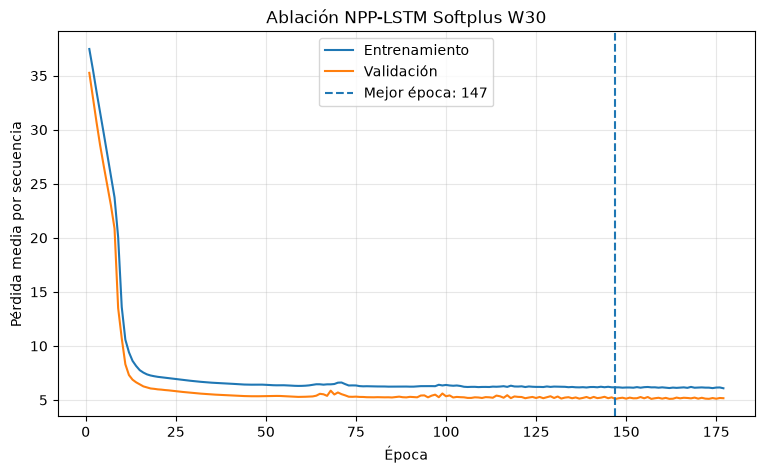

In [4]:
hist = pd.read_csv(ruta_historial)

plt.figure(figsize=(9, 5))

plt.plot(
    hist["epoca"], hist["loss"],
    label="Entrenamiento"
)

plt.plot(
    hist["epoca"], hist["val_loss"],
    label="Validación"
)

plt.axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)

plt.xlabel("Época")
plt.ylabel("Pérdida media por secuencia")
plt.title(f"Ablación NPP-LSTM Softplus W{VENTANA}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
resultados = []

for ventana in [10, 20, 30]:

    ruta = (
        raiz / "results" /
        f"historial_NPP_softplus_W{ventana}.csv"
    )

    hist = pd.read_csv(ruta)

    mejor = hist.loc[hist["val_loss"].idxmin()]

    resultados.append({
        "Ventana": ventana,
        "Mejor epoca": int(mejor["epoca"]),
        "Mejor val_loss": float(mejor["val_loss"]),
        "Epocas ejecutadas": len(hist)
    })

comparacion = pd.DataFrame(resultados)

comparacion = comparacion.sort_values(
    "Mejor val_loss"
)

display(comparacion)

,Ventana,Mejor epoca,Mejor val_loss,Epocas ejecutadas
1,20,282,4.996779,312
2,30,147,5.093944,177
0,10,182,5.098294,212


In [6]:
comparacion.to_csv(
    raiz / "results/ablacion_ventanas.csv",
    index=False
)